# 04 — ECG Segmentation

Sinyal hasil denoising dipotong menjadi window **3.136 sampel** dengan hop **784 sampel** (overlap 75%). Pada sinyal 65.536 sampel, jumlah window adalah 80 per rekaman.

In [1]:
from pathlib import Path
import os, json, pickle, warnings
import numpy as np
import pandas as pd

ROOT = Path("..") if Path("..").exists() else Path(".")
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WORK_DIR = DATA_DIR / "processed"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

CLASS_NAMES = ["CHF", "NSR"]
FS_TARGET = 128
RECORD_LENGTH = 65536
WINDOW_LENGTH = 3136
HOP_LENGTH = 784

IN_DIR = WORK_DIR / "03_denoised"
IN_MANIFEST = IN_DIR / "manifest_denoised.csv"
OUT_DIR = WORK_DIR / "04_segments"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
manifest = pd.read_csv(IN_MANIFEST)
manifest = manifest[manifest["label"].isin(CLASS_NAMES)].reset_index(drop=True)
if set(manifest["label"]) != set(CLASS_NAMES):
    raise ValueError(f"Manifest segmentasi harus berisi CHF dan NSR; ditemukan: {sorted(set(manifest['label']))}")
segments, labels, record_ids, segment_ids = [], [], [], []

for _, row in manifest.iterrows():
    x = np.load(row["path"]).astype(np.float32)
    if len(x) < WINDOW_LENGTH:
        warnings.warn(f"Rekaman {row['record_id']} terlalu pendek; dilewati.")
        continue
    starts = range(0, len(x)-WINDOW_LENGTH+1, HOP_LENGTH)
    for seg_idx, start in enumerate(starts):
        seg = x[start:start+WINDOW_LENGTH]
        segments.append(seg)
        labels.append(row["label"])
        record_ids.append(row["record_id"])
        segment_ids.append(seg_idx)

X = np.stack(segments).astype(np.float32)
meta = pd.DataFrame({"label": labels, "record_id": record_ids, "segment_id": segment_ids})
np.save(OUT_DIR / "segments.npy", X)
meta.to_csv(OUT_DIR / "segments_metadata.csv", index=False)
print("Bentuk X:", X.shape)
display(meta.groupby("label").size().rename("jumlah_segment"))
print("Jumlah segmen per rekaman (seharusnya 80 jika panjang 65536):")
display(meta.groupby("record_id").size().value_counts().sort_index())

Bentuk X: (5280, 3136)


label
CHF    2400
NSR    2880
Name: jumlah_segment, dtype: int64

Jumlah segmen per rekaman (seharusnya 80 jika panjang 65536):


80    66
Name: count, dtype: int64

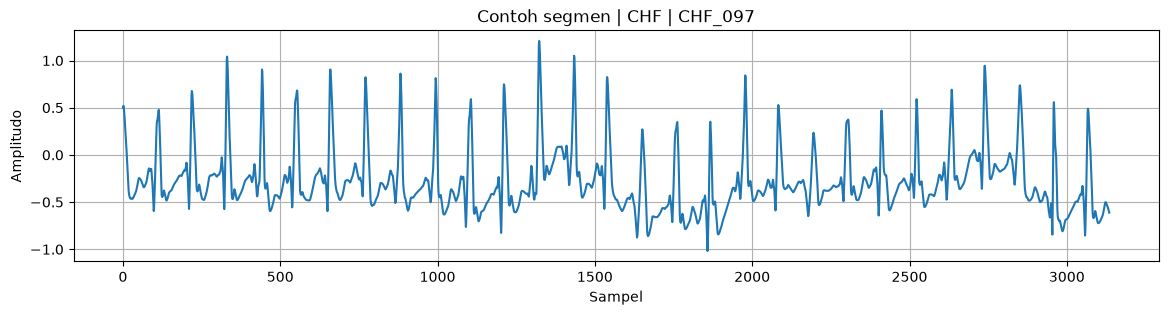

In [3]:
i = 0
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 3))
plt.plot(X[i])
plt.title(f"Contoh segmen | {meta.iloc[i]['label']} | {meta.iloc[i]['record_id']}")
plt.xlabel("Sampel"); plt.ylabel("Amplitudo"); plt.grid(True); plt.show()

Jangan membagi train/test secara acak per segmen. Window yang berasal dari rekaman sama saling tumpang tindih, sehingga pembagian acak dapat menyebabkan data yang hampir sama masuk ke train dan test. Pembagian berdasarkan `record_id` dilakukan pada notebook 06.